**New benchmark analysis (2026-10-05).** Uses the available 4L/2H/K16 checkpoints with weight decay **0.1**, seeds 100–104. This is a new exploratory analysis, not reproduction of SEL-4L wd0.01. References/conflict definitions are frozen historical inputs, verified by hash. All model-dependent outputs are recomputed. Validation match splits support the stated comparisons; prior test access prevents a fresh confirmatory claim. Population and intervention scope apply to each reported result. See `config/analysis_plan.json` and `SURGICAL_FIXES.md`.

# MB08 — MLPs: Transform, Pass On, or Combine?

**Track B · Mechanistic interpretability of SEL-4L · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | Do the four MLPs (128 → 512 → 128, GELU) transform or combine identity and context information, or only pass on what attention and the embedding already put into the residual stream? |
| **Experiment** | E15 |
| **Population** | P-player validation (estimation half for every estimate; discovery half only for ranking neurons); matched non-conflict controls; index-0 conflict rows; scored validation events for NLL; the E8 factorial units of MB04 |
| **Outputs** | `results/MB08_transform_or_pass.csv`, `results/MB08_ablation.parquet`, `results/MB08_ablation_summary.csv`, `results/MB08_combination.csv`, `results/MB08_neurons.csv`, `results/MB08_summary.json`, `figures/MB08_*` |
| **Modules** | uses `patching.py`, `circuits.py` |
| **Test data** | none |


In [1]:
import os
for _thread_var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_thread_var] = os.environ.get("MI_CPU_THREADS", "4")
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: True | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(int(os.environ.get("MI_CPU_THREADS", "4")))
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified = fingerprint.verify_files(MANIFEST)
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])

SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
print(f"verified files: {len(verified)} | primary seed {PRIMARY_SEED} | identity variable: {IDENTITY}")
print(val_conflicts.groupby(["population", "half"]).size().unstack().to_string())

partners = pd.read_parquet(POP / "swap_partners.parquet")
donors = pd.read_parquet(POP / "context_donors.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
reference = torch.load(POP / "reference_means.pt", map_location="cpu", weights_only=False)
MEANS = {site: value.to(DEVICE) for site, value in reference["means"].items()}
REFERENCE_WINDOWS = np.asarray(reference["windows"])
p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
p_player = p_player.merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
index0 = val_conflicts[val_conflicts.population == "index-0"].reset_index(drop=True)
nll_table = circuits.scored_events(val_view, targets, bundle["match_ids"],
                                   limit=None if RUN_MODE == "full" else SETTINGS["max_events"] * 3)
MLPS = [f"L{l}MLP" for l in range(N_LAYERS)]
candidates = mi_setup.load_json(OUT / "config" / "candidates.json")
print(f"P-player rows: {len(p_player):,} | controls: {len(controls):,} | index-0: {len(index0):,} | NLL events: {len(nll_table):,}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 53 | primary seed 103 | identity variable: player
half        discovery  estimation
population                       
P-player         1215         529
index-0          4296        4651
P-player rows: 1,744 | controls: 252 | index-0: 8,947 | NLL events: 68,003


## 1. Terms

| Term | Meaning here |
|---|---|
| **MLP** | A two-layer network applied to each position on its own (LayerNorm → 128 → 512 → GELU → 128). It cannot move information between positions. |
| **Hidden unit (neuron)** | One of the 512 values inside an MLP after the GELU. |
| **MLP input / output / block output** | `mlp_in_l`: the residual stream the MLP reads (only the MLP sees a patch here); `mlp_out_l`: what the MLP adds to the residual stream; `resid_post_l`: the residual stream leaving the block (input + MLP output). |
| **Attribution patching** | A first-order estimate of what patching each hidden unit would do (activation difference × gradient of Δ). Used only to *rank* units before real ablation (Syed et al. 2023; Nanda 2023). |

## 2. Transform or pass? (target position)

**Research question.** Does information about the player (or the context) that reaches the arbitration pass *through* the MLP of a layer, *around* it through the residual path, or is it *written* by the MLP?

**Design.** Denoising at the target position under the identity-removal contrast (I1) and the context contrast (MB06 definitions); at each layer l three patches, each in its own run:

1. **Around the MLP:** the residual stream entering the MLP sub-block (`resid_mid_l`) is set to its clean value while the MLP's own output (`mlp_out_l`) is held at its corrupted value, so the clean information reaches later layers only by the path that bypasses the MLP.
2. **MLP output:** only `mlp_out_l` is set to its clean value; everything else stays corrupted.
3. **Block output:** `resid_post_l` (= 1 and 2 together) is set to its clean value.

Patching the MLP's *input* alone is not used: an MLP acts on each position separately, so at a single position a clean input always produces exactly the clean output, and that patch would repeat (2).

**Reading rule (fixed before results).** If (1) ≈ (3) and (2) ≈ 0, the information passes around the MLP unchanged. If (2) is a substantial share of (3), the MLP writes information that matters for Δ, i.e. it transforms what it reads. If (1) + (2) differs clearly from (3), the two routes interact (later layers need both).

**Statistic.** Pooled recovery R with match-bootstrap interval, estimation half.

In [4]:
ROUTES = ["(1) around the MLP", "(2) MLP output", "(3) block output"]

def corrupted_inputs(contrast, inputs, positions, chunk):
    if contrast == "identity removal":
        return interventions.remove_feature(inputs, IDENTITY, positions)
    donor_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
    return interventions.write_identity(donor_inputs, inputs, positions, ["player"])

estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
transform_records = []
with torch.no_grad():
    for contrast in ["identity removal", "context"]:
        table = estimation if contrast != "context" else estimation[estimation["donor_window"].notna()].reset_index(drop=True)
        if contrast == "context":
            table["donor_window"] = table["donor_window"].astype(int)
        sites = [f"{kind}_{l}" for l in range(N_LAYERS) for kind in ["resid_mid", "mlp_out", "resid_post"]]
        for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
            chunk = table.iloc[part]
            corrupted = corrupted_inputs(contrast, inputs, positions, chunk)
            clean_logits, clean = hooks.forward(MODEL, inputs, capture=sites)
            corrupt_logits, corrupt = hooks.forward(MODEL, corrupted, capture=sites)
            m_clean = mi_metrics.delta(mi_metrics.at_target(clean_logits, positions), a_ctx, a_id)
            m_corrupt = mi_metrics.delta(mi_metrics.at_target(corrupt_logits, positions), a_ctx, a_id)
            for layer in range(N_LAYERS):
                patches = {
                    "(1) around the MLP": {f"resid_mid_{layer}": hooks.copy_at(clean[f"resid_mid_{layer}"], positions),
                                           f"mlp_out_{layer}": hooks.copy_at(corrupt[f"mlp_out_{layer}"], positions)},
                    "(2) MLP output": {f"mlp_out_{layer}": hooks.copy_at(clean[f"mlp_out_{layer}"], positions)},
                    "(3) block output": {f"resid_post_{layer}": hooks.copy_at(clean[f"resid_post_{layer}"], positions)},
                }
                for route, replace in patches.items():
                    m_patched = circuits.delta_under(MODEL, corrupted, positions, a_ctx, a_id, replace)
                    transform_records.append(pd.DataFrame({"match_id": chunk["match_id"].to_numpy(), "contrast": contrast,
                                                           "layer": f"L{layer}", "site": route,
                                                           "raw_change": m_patched - m_corrupt, "total": m_clean - m_corrupt}))
transform = pd.concat(transform_records, ignore_index=True)
transform_rows = []
for (contrast, layer, site), group in transform.groupby(["contrast", "layer", "site"], sort=False):
    pooled = mi_metrics.pooled_recovery(group["raw_change"], group["total"], group["match_id"], N_BOOT)
    transform_rows.append({"contrast": contrast, "layer": layer, "site": site, "pooled recovery": pooled["recovery"],
                           "CI low": pooled["ci_low"], "CI high": pooled["ci_high"], "n": len(group)})
transform_table = pd.DataFrame(transform_rows)
transform_table.to_csv(OUT / "results" / "MB08_transform_or_pass.csv", index=False)
wide = transform_table.pivot_table(index=["contrast", "layer"], columns="site", values="pooled recovery")[ROUTES]
wide["(1) + (2) - (3)"] = wide[ROUTES[0]] + wide[ROUTES[1]] - wide[ROUTES[2]]
print(wide.round(3).to_string())
print()
print(transform_table.round(3).to_string(index=False))

site                    (1) around the MLP  (2) MLP output  (3) block output  (1) + (2) - (3)
contrast         layer                                                                       
context          L0                  0.207           0.624             0.989           -0.159
                 L1                  0.474           0.432             0.994           -0.088
                 L2                  0.508           0.425             0.993           -0.060
                 L3                  0.407           0.706             1.000            0.113
identity removal L0                  0.366           0.598             1.000           -0.035
                 L1                  0.497           0.479             1.000           -0.025
                 L2                  0.567           0.413             1.000           -0.020
                 L3                  0.411           0.572             1.000           -0.018

        contrast layer               site  pooled recovery 

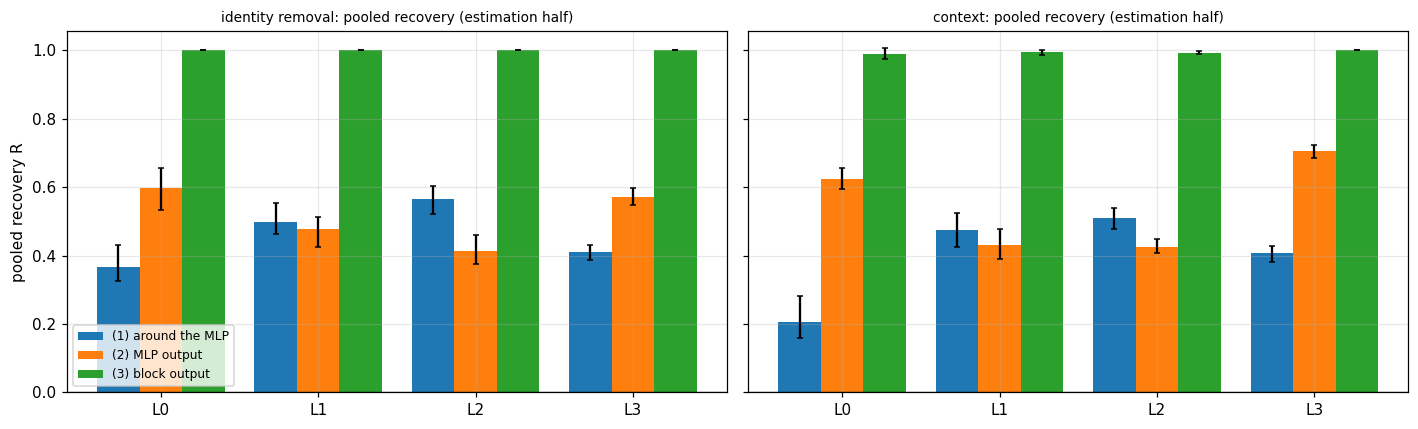

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axis, contrast in zip(axes, ["identity removal", "context"]):
    frame = transform_table[transform_table.contrast == contrast]
    for offset, site in enumerate(ROUTES):
        part = frame[frame.site == site]
        x = np.arange(len(part)) + (offset - 1) * 0.27
        axis.bar(x, part["pooled recovery"], width=0.27, label=site,
                 yerr=[part["pooled recovery"] - part["CI low"], part["CI high"] - part["pooled recovery"]], capsize=2)
    axis.set_xticks(range(N_LAYERS)); axis.set_xticklabels([f"L{l}" for l in range(N_LAYERS)])
    axis.axhline(0, color="black", linewidth=0.8); axis.set_title(f"{contrast}: pooled recovery (estimation half)", fontsize=9)
axes[0].legend(fontsize=8); axes[0].set_ylabel("pooled recovery R")
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB08_transform_or_pass.png", bbox_inches="tight"); plt.show()

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 3. Necessity of each MLP

**Research question.** Is an MLP necessary for Δ on conflicts, and specifically so?

**Design and statistics.** As in MB07 Section 7: each `mlp_out_l` is mean-ablated and resample-ablated (`n_draws` draws), at the target position and at every position; change in Δ on P-player conflicts, matched controls and index-0 conflicts, and change in NLL on scored validation events. Specificity = |change on the conflict| − |change on its matched control|. Estimation half; Benjamini–Hochberg over the 4 MLPs within each method × scope.

In [6]:
tables = {"P-player": p_player, "matched controls": controls, "index-0": index0}
panel = circuits.AblationPanel(MODEL, bundle, val_view, tables, nll_table, BATCH)
records = []
generator = torch.Generator().manual_seed(0)
start = time.time()
for mlp in MLPS:
    print(f"Starting {mlp} ablations", flush=True)
    for scope, at_target in [("target", True), ("all positions", False)]:
        changes, nll_change = panel.changes(lambda: circuits.mean_ablation([mlp], MEANS, at_target))
        records.append(panel.rows(mlp, "mean", scope, changes, nll_change))
        changes, nll_change = panel.changes(lambda: circuits.resample_ablation(MODEL, bundle, val_view, REFERENCE_WINDOWS, [mlp],
                                                                               at_target, generator), SETTINGS["n_draws"])
        records.append(panel.rows(mlp, "resample", scope, changes, nll_change))
        print(f"Completed {mlp} / {scope}; cumulative {time.time()-start:.1f}s", flush=True)
mlp_ablation = pd.concat(records, ignore_index=True)
mlp_ablation.to_parquet(OUT / "results" / "MB08_ablation.parquet", index=False)
mlp_summary = circuits.summarise_ablation(mlp_ablation, controls, N_BOOT)
mlp_summary.to_csv(OUT / "results" / "MB08_ablation_summary.csv", index=False)
show = ["unit", "method", "scope", "P-player: mean change", "P-player: CI low", "P-player: CI high", "P-player: q",
        "matched controls: mean change", "index-0: mean change", "NLL (scored events): mean change",
        "specificity: mean", "specificity: CI low", "specificity: q"]
print(f"done in {time.time() - start:.0f} s")
print(mlp_summary[[c for c in show if c in mlp_summary]].round(4).to_string(index=False))

Starting L0MLP ablations


Completed L0MLP / target; cumulative 32.4s


Completed L0MLP / all positions; cumulative 65.1s


Starting L1MLP ablations


Completed L1MLP / target; cumulative 97.3s


...

Completed L2MLP / all positions; cumulative 194.2s


Starting L3MLP ablations


Completed L3MLP / target; cumulative 226.2s


Completed L3MLP / all positions; cumulative 257.3s


done in 258 s
 unit   method         scope  P-player: mean change  P-player: CI low  P-player: CI high  P-player: q  matched controls: mean change  index-0: mean change  NLL (scored events): mean change  specificity: mean  specificity: CI low  specificity: q
L0MLP     mean        target                -7.5110           -8.2291            -6.4731        0.001                        -3.9148               -7.8853                            0.9332             1.1271               0.7268          0.0010
L0MLP resample        target                -8.3076           -8.7900            -7.6250        0.001                        -4.7339               -8.4763                            1.8383             1.7060               0.6605          0.0020
L0MLP     mean all positions                -7.0603           -7.7209            -6.0784        0.001                        -3.5549               -7.4255                            0.8375             1.1327               0.6934          0.0010
L0MLP 

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 4. Combination test — where do identity and context combine?

**Research question.** If MB04's E8 found an identity × context interaction beyond the LayerNorm floor, which MLP produces it?

**Design.** The E8 factorial (players A, B × contexts X, Y; MB04) is recomputed with one MLP at a time frozen, at every position, to its value in the A-run of the same context. Freezing MLP l stops the player swap from changing that MLP's output, so any interaction that MLP l creates disappears.

```latex
I = m(A,X) - m(A,Y) - m(B,X) + m(B,Y), \qquad I_{l} = \text{the same with MLP } l \text{ frozen}
```

**Statistic.** Per unit, |I| − |I_l| (paired); match-bootstrap interval and one-sided p-value (greater); Benjamini–Hochberg over the 4 layers. The share of the interaction beyond the floor that freezing removes is reported as a pooled ratio Σ(|I| − |I_l|) / Σ(|I| − |I_floor|). Estimation half.

In [7]:
combination_rows = []
if IDENTITY == "player":
    units = p_player[p_player["donor_window"].notna()].copy()
    units["donor_window"] = units["donor_window"].astype(int)
    units["partner"] = [partner_of.get(p, -1) for p in units["player"]]
    units = units[(units["partner"] > 0) & (units.half == "estimation")].reset_index(drop=True)
    all_frozen = [f"attn_out_{l}" for l in range(N_LAYERS)] + [f"mlp_out_{l}" for l in range(N_LAYERS)]
    with torch.no_grad():
        for part in mi_setup.batch_slices(len(units), BATCH):
            chunk = units.iloc[part]
            x_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["window"].to_numpy())
            y_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
            positions = torch.as_tensor(chunk["position"].to_numpy(), device=DEVICE)
            a_ctx = torch.as_tensor(chunk["a_ctx"].to_numpy(), device=DEVICE); a_id = torch.as_tensor(chunk["a_id"].to_numpy(), device=DEVICE)
            player_a = torch.as_tensor(chunk["player"].to_numpy(), device=DEVICE)
            player_b = torch.as_tensor(chunk["partner"].to_numpy(), device=DEVICE)
            cells = {}
            for context_name, context_inputs in [("X", x_inputs), ("Y", y_inputs)]:
                with_a = interventions.set_feature(context_inputs, "player", positions, player_a)
                with_b = interventions.set_feature(context_inputs, "player", positions, player_b)
                logits_a, cache_a = hooks.forward(MODEL, with_a, capture=all_frozen)
                cells[("A", context_name, "none")] = mi_metrics.delta(mi_metrics.at_target(logits_a, positions), a_ctx, a_id)
                cells[("B", context_name, "none")] = circuits.delta_under(MODEL, with_b, positions, a_ctx, a_id)
                floor = {site: (lambda value, kept=cache_a[site]: kept) for site in all_frozen}
                cells[("B", context_name, "floor")] = circuits.delta_under(MODEL, with_b, positions, a_ctx, a_id, floor)
                for layer in range(N_LAYERS):
                    frozen = {f"mlp_out_{layer}": (lambda value, kept=cache_a[f"mlp_out_{layer}"]: kept)}
                    cells[("B", context_name, f"L{layer}MLP")] = circuits.delta_under(MODEL, with_b, positions, a_ctx, a_id, frozen)
            def interaction(condition):
                return cells[("A", "X", "none")] - cells[("A", "Y", "none")] - cells[("B", "X", condition)] + cells[("B", "Y", condition)]
            row = {"event_row": chunk["event_row"].to_numpy(), "match_id": chunk["match_id"].to_numpy(),
                   "I": interaction("none"), "I_floor": interaction("floor")}
            for layer in range(N_LAYERS):
                row[f"I_L{layer}MLP_frozen"] = interaction(f"L{layer}MLP")
            combination_rows.append(pd.DataFrame(row))
combination = pd.concat(combination_rows, ignore_index=True) if combination_rows else pd.DataFrame()
combination_summary = []
if len(combination):
    beyond_floor = np.abs(combination["I"]) - np.abs(combination["I_floor"])
    for mlp in MLPS:
        removed = np.abs(combination["I"]) - np.abs(combination[f"I_{mlp}_frozen"])
        summary = mi_metrics.summarise(removed, combination["match_id"], N_BOOT)
        share = mi_metrics.pooled_recovery(removed, beyond_floor, combination["match_id"], N_BOOT)
        combination_summary.append({"MLP frozen": mlp, "mean |I|": np.abs(combination["I"]).mean(),
                                    "mean |I_floor|": np.abs(combination["I_floor"]).mean(),
                                    "mean |I_l|": np.abs(combination[f"I_{mlp}_frozen"]).mean(),
                                    "mean (|I| - |I_l|)": summary["mean"], "CI low": summary["ci_low"], "CI high": summary["ci_high"],
                                    "p (greater)": mi_metrics.bootstrap_pvalue(removed, combination["match_id"], N_BOOT, alternative="greater"),
                                    "share of interaction beyond floor removed": share["recovery"],
                                    "share CI low": share["ci_low"], "share CI high": share["ci_high"], "n units": len(combination)})
    combination_summary = pd.DataFrame(combination_summary)
    combination_summary["q (BH over 4 layers)"] = mi_metrics.benjamini_hochberg(combination_summary["p (greater)"].to_numpy(), 0.05)[1]
    combination_summary.to_csv(OUT / "results" / "MB08_combination.csv", index=False)
    print(combination_summary.round(4).to_string(index=False))
else:
    combination_summary = pd.DataFrame()
    print("combination test not run (identity variable is not the player, or no factorial units)")

MLP frozen  mean |I|  mean |I_floor|  mean |I_l|  mean (|I| - |I_l|)  CI low  CI high  p (greater)  share of interaction beyond floor removed  share CI low  share CI high  n units  q (BH over 4 layers)
     L0MLP    0.8307          0.0438      0.4131              0.4176  0.3462   0.5028       0.0005                                     0.5536        0.4974         0.5998      529                0.0005
     L1MLP    0.8307          0.0438      0.4594              0.3713  0.3167   0.4289       0.0005                                     0.4871        0.4444         0.5287      529                0.0005
     L2MLP    0.8307          0.0438      0.4599              0.3708  0.3347   0.4152       0.0005                                     0.4826        0.4605         0.5104      529                0.0005
     L3MLP    0.8307          0.0438      0.3501              0.4807  0.4349   0.5401       0.0005                                     0.6217        0.5998         0.6551      529             

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 5. Neurons (only for an MLP that qualified)

**Rule (fixed before results).** An MLP qualifies if its output is an MB06 candidate (any contrast) or its mean ablation at every position has P-player q < 0.05 in Section 3. For each qualifying MLP:

1. Rank its 512 hidden units on the **discovery half** by attribution patching under I1: mean over events of sign(d) × (clean − corrupted hidden value) × ∂Δ/∂(hidden value) in the corrupted run, at the target, with d = Δ_clean − Δ_I1 of the event; the largest values first (the units estimated to restore most of each event's own identity effect).
2. On the **estimation half**, mean-ablate (at the target, in both the recorded and the I1 run) the top k = 5, 10, 20, 50 units, and as the control `n_random_circuits` random sets of the same size; the measure is the reduction of the identity effect, sign(d) × (d_intact − d_ablated), so that a positive value always means the effect shrank.
3. Report the top-k effect as a percentile of the random-set distribution. A single unit is described individually only if its own ablation effect lies outside the distribution of `n_random_circuits` single random units.

In smoke mode, if no MLP qualifies, the section runs on the MLP with the largest ablation effect **only to check the code**.

In [8]:
qualifying = set()
for item in candidates["candidates"]:
    if "mlp_out" in item["site"]:
        qualifying.add(f"{item['site'][:2]}MLP")
significant = mlp_summary[(mlp_summary.method == "mean") & (mlp_summary.scope == "all positions") & (mlp_summary["P-player: q"] < 0.05)]
qualifying |= set(significant["unit"])
qualifying = sorted(qualifying)
code_check_only = False
if not qualifying and RUN_MODE == "smoke":
    ranked = mlp_summary[(mlp_summary.method == "mean") & (mlp_summary.scope == "all positions")]
    qualifying = [ranked.loc[ranked["P-player: mean change"].abs().idxmax(), "unit"]]
    code_check_only = True
print("qualifying MLPs:", qualifying if qualifying else "none -> section skipped", "| code check only:", code_check_only)

qualifying MLPs: ['L0MLP', 'L1MLP', 'L2MLP', 'L3MLP'] | code check only: False


In [9]:
def remove_player(inputs, positions, chunk):
    return interventions.remove_feature(inputs, IDENTITY, positions)

def attribution_scores(layer, table):
    site = f"mlp_hidden_{layer}"
    total = None
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        corrupted = remove_player(inputs, positions, None)
        with torch.no_grad():
            clean_logits, clean_cache = hooks.forward(MODEL, inputs, capture=[site])
            corrupt_logits, _ = hooks.forward(MODEL, corrupted)
            sign = torch.as_tensor(np.sign(mi_metrics.delta(mi_metrics.at_target(clean_logits, positions), a_ctx, a_id)
                                           - mi_metrics.delta(mi_metrics.at_target(corrupt_logits, positions), a_ctx, a_id)),
                                   dtype=clean_cache[site].dtype, device=DEVICE)
        holder = {}
        def keep(value):
            leaf = value.detach().requires_grad_(True)
            holder["leaf"] = leaf
            return leaf
        with torch.enable_grad():
            logits, _ = hooks.forward(MODEL, corrupted, replace={site: keep})
            target_logits = mi_metrics.at_target(logits, positions)
            rows = torch.arange(len(positions), device=DEVICE)
            (target_logits[rows, a_ctx] - target_logits[rows, a_id]).sum().backward()
        leaf = holder["leaf"]
        difference = clean_cache[site][rows, positions] - leaf.detach()[rows, positions]
        score = (sign.unsqueeze(1) * difference * leaf.grad[rows, positions]).sum(0)
        total = score if total is None else total + score
    return (total / len(table)).cpu().numpy()

def unit_ablation(layer, units, mean_hidden):
    site = f"mlp_hidden_{layer}"
    units = torch.as_tensor(np.asarray(units), device=DEVICE)
    def builder(inputs, positions):
        def edit(value):
            new = value.clone()
            rows = torch.arange(value.shape[0], device=value.device)
            new[rows.unsqueeze(1), positions.unsqueeze(1), units.unsqueeze(0)] = mean_hidden[positions][:, units]
            return new
        return {site: edit}
    return builder

neuron_rows, single_rows = [], []
if qualifying:
    discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
    estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
    clean_intact, corrupt_intact = circuits.identity_effects(MODEL, bundle, val_view, estimation, BATCH, remove_player)
    intact_effect = clean_intact - corrupt_intact
    rng = np.random.default_rng(0)
    for mlp in qualifying:
        layer = int(mlp[1])
        hidden_mean = mi_setup.reference_means(MODEL, bundle, val_view, REFERENCE_WINDOWS, [f"mlp_hidden_{layer}"], BATCH,
                                               hooks.forward)[f"mlp_hidden_{layer}"]
        scores = attribution_scores(layer, discovery)
        order = np.argsort(-scores)
        n_units = len(scores)
        def reduction(units):
            clean, corrupt = circuits.identity_effects(MODEL, bundle, val_view, estimation, BATCH, remove_player,
                                                       unit_ablation(layer, units, hidden_mean))
            return mi_metrics.aligned(intact_effect - (clean - corrupt), intact_effect)
        for k in [5, 10, 20, 50]:
            top = reduction(order[:k])
            summary = mi_metrics.summarise(top, estimation["match_id"], N_BOOT)
            random_means = [float(reduction(rng.choice(n_units, size=k, replace=False)).mean()) for _ in range(SETTINGS["n_random_circuits"])]
            neuron_rows.append({"MLP": mlp, "k": k, "mean reduction of identity effect (top k)": summary["mean"],
                                "CI low": summary["ci_low"], "CI high": summary["ci_high"],
                                "random sets: median": float(np.median(random_means)),
                                "random sets: 95th percentile": float(np.percentile(random_means, 95)),
                                "percentile of top k among random sets": float((np.array(random_means) < summary["mean"]).mean() * 100),
                                "n random sets": len(random_means), "code check only": code_check_only})
        single_random = [float(reduction([unit]).mean()) for unit in rng.choice(n_units, size=min(SETTINGS["n_random_circuits"], n_units), replace=False)]
        for rank, unit in enumerate(order[:10]):
            effect = float(reduction([unit]).mean())
            single_rows.append({"MLP": mlp, "rank": rank + 1, "unit": int(unit), "attribution score": float(scores[unit]),
                                "mean reduction (single unit)": effect,
                                "random single units: 2.5th percentile": float(np.percentile(single_random, 2.5)),
                                "random single units: 97.5th percentile": float(np.percentile(single_random, 97.5)),
                                "outside random distribution": bool(effect < np.percentile(single_random, 2.5) or effect > np.percentile(single_random, 97.5))})
neurons = pd.DataFrame(neuron_rows); singles_table = pd.DataFrame(single_rows)
neurons.to_csv(OUT / "results" / "MB08_neurons.csv", index=False)
singles_table.to_csv(OUT / "results" / "MB08_single_neurons.csv", index=False)
print(neurons.round(4).to_string(index=False) if len(neurons) else "no MLP qualified; neuron analysis skipped")
print(singles_table.round(4).to_string(index=False) if len(singles_table) else "")

  MLP  k  mean reduction of identity effect (top k)  CI low  CI high  random sets: median  random sets: 95th percentile  percentile of top k among random sets  n random sets  code check only
L0MLP  5                                    -0.0621 -0.1361   0.0070              -0.0014                        0.0044                                    0.0            100            False
L0MLP 10                                     0.0022 -0.1169   0.1163              -0.0028                        0.0071                                   81.0            100            False
L0MLP 20                                     0.0887 -0.0565   0.2215              -0.0094                        0.0097                                  100.0            100            False
L0MLP 50                                     0.2150  0.0980   0.3283              -0.0313                        0.0065                                  100.0            100            False
L1MLP  5                                    -

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

In [10]:
mi_setup.save_json(OUT / "results" / "MB08_summary.json", {
    "transform_or_pass": transform_table.to_dict(orient="records"), "ablation": mlp_summary.to_dict(orient="records"),
    "combination": combination_summary.to_dict(orient="records") if len(combination_summary) else [],
    "qualifying_mlps": qualifying, "neuron_section_code_check_only": code_check_only,
    "neurons": neurons.to_dict(orient="records"), "run_mode": RUN_MODE})
fingerprint.record_files(MANIFEST, {"results/MB08_summary.json": OUT / "results" / "MB08_summary.json",
                                    "results/MB08_ablation.parquet": OUT / "results" / "MB08_ablation.parquet"})
fingerprint.register(REGISTRY, {"notebook": "MB08", "experiment": "E15 MLPs", "seed": PRIMARY_SEED,
                                "qualifying_mlps": qualifying, "run_mode": RUN_MODE})
print("saved")

saved
